---
title: "Hierarchical Modeling with PyMC" 
author: "Sheng Long"
date: "12/16/25"
abstract: |
    Implemented the reedfrog example mentioned in *Statistical Rethinking* with `PyMC`. 
keywords: 
    - statistics 
format:
    html:
        code-fold: false
---

In [15]:
import pandas as pd
import pymc as pm
import arviz as az

We will use the tadpole survival in ponds dataset used in McElreath's *Statistical Rethinking* textbook. The `reedfrogs.csv` is obtained from [here](https://github.com/rmcelreath/rethinking/blob/master/data/reedfrogs.csv). One can follow along the original textbook starting from *Chapter 13.1 Example: Multilevel tadpoles*. 

In [18]:
df = pd.read_csv("reedfrogs.csv", delimiter=";")
df

,density,pred,size,surv,propsurv
0,10,no,big,9,0.900000
1,10,no,big,10,1.000000
2,10,no,big,7,0.700000
3,10,no,big,10,1.000000
4,10,no,small,9,0.900000
5,10,no,small,9,0.900000
6,10,no,small,10,1.000000
7,10,no,small,9,0.900000
8,10,pred,big,4,0.400000
9,10,pred,big,9,0.900000


We will focus on the number surviving (`surv`) out of an intial count (`density`). 

# No pooling 

Math model: 

$$
\begin{align}
\texttt{surv}_i &\sim \text{Binomial}(\texttt{density}_i, p_i) \\ 
\text{logit}(p_i) &= \alpha_{i} \\ 
\alpha_j &\sim \mathcal{N}(0, 1.5), j \in [48]
\end{align}
$$

In [42]:
# corresponds to R code 13.2
with pm.Model() as model_1:
    # prior 
    alpha = pm.Normal("alpha", 0, 1.5, shape = len(df))
    # link 
    p_survived = pm.Deterministic("p_survived", pm.math.invlogit(alpha))
    # likelihood 
    survived = pm.Binomial("survived", n=df.density, p=p_survived, observed=df.surv)

    model_1_trace = pm.sample()
    model_1_trace = pm.compute_log_likelihood(model_1_trace)
    # posterior predictive check 
    pm.sample_posterior_predictive(model_1_trace, extend_inferencedata=True)


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha]


                                                                        
                            Step     Grad     Sampl…                    
  Progr…   Draws   Diver…   size     evals    Speed    Elaps…   Remai…  
 ────────────────────────────────────────────────────────────────────── 
  ━━━━━━   0       0        0.000    0        0.00     0:00:…   -:--:…  
                                              draws…                    
  ━━━━━━   0       0        0.000    0        0.00     0:00:…   -:--:…  
                                              draws…                    
  ━━━━━━   0       0        0.000    0        0.00     0:00:…   -:--:…  
                                              draws…                    
  ━━━━━━   0       0        0.000    0        0.00     0:00:…   -:--:…  
                                              draws…                    
                                                                        
                            Step     Grad     Sampl

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 15 seconds.


Computing ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00:--:--


Sampling: [survived]


Sampling ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00 / 0:00:00;237m━━  93% 0:00:01 / 0:00:00


In [34]:
# check output 
az.summary(model_1_trace)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha[0],1.721,0.770,0.313,3.156,0.009,0.014,7915.0,3012.0,1.0
alpha[1],2.421,0.917,0.835,4.244,0.011,0.019,8674.0,2663.0,1.0
alpha[2],0.752,0.636,-0.438,1.955,0.007,0.012,8628.0,2899.0,1.0
alpha[3],2.420,0.890,0.858,4.180,0.011,0.017,8017.0,2527.0,1.0
alpha[4],1.713,0.752,0.367,3.198,0.008,0.015,8495.0,2593.0,1.0
...,...,...,...,...,...,...,...,...,...
p_survived[43],0.403,0.079,0.247,0.545,0.001,0.001,10045.0,3206.0,1.0
p_survived[44],0.622,0.079,0.482,0.780,0.001,0.001,8452.0,2853.0,1.0
p_survived[45],0.352,0.076,0.212,0.497,0.001,0.001,8038.0,2839.0,1.0
p_survived[46],0.863,0.054,0.762,0.952,0.001,0.001,8130.0,2743.0,1.0


[autoreload of cutils_ext failed: Traceback (most recent call last):
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 580, in superreload
    module = reload(module)
  File "/Users/shenglong/.local/share/uv/python/cpython-3.13.9-macos-x86_64-none/lib/python3.13/importlib/__init__.py", line 128, in reload
    raise ModuleNotFoundError(f"spec not found for the module {name!r}", name=name)
ModuleNotFoundError: spec not found for the module 'cutils_ext'
]


array([[<Axes: title={'center': 'alpha'}>,
        <Axes: title={'center': 'alpha'}>],
       [<Axes: title={'center': 'p_survived'}>,
        <Axes: title={'center': 'p_survived'}>]], dtype=object)

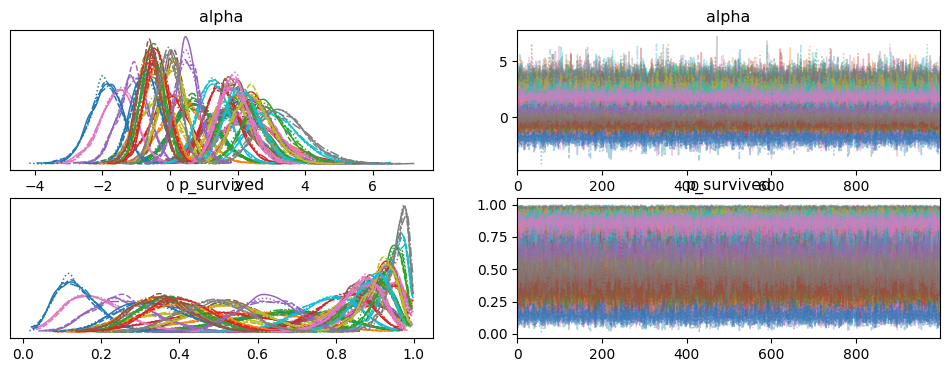

In [44]:
az.plot_trace(model_1_trace)

<Axes: xlabel='survived'>

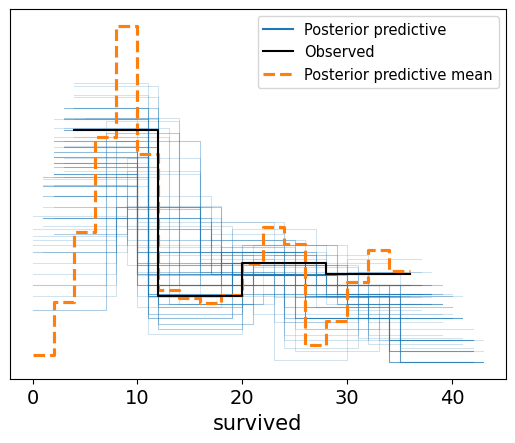

In [45]:
# pp check 
az.plot_ppc(model_1_trace, num_pp_samples=100)

# With pooling 

Math model: 
$$
\begin{align}
\texttt{surv}_i &\sim \text{Binomial}(N_i, p_i) \\ 
\text{logit}(p_i) &\sim \alpha_{\text{TANK}[i]} \\ 
\alpha_j &\sim \mathcal{N}(\bar{\alpha}, \sigma), j \in [48] \\ 
\bar{\alpha} &\sim \mathcal{N}(0, 1.5) \\ 
\sigma &\sim \text{Exponential}(1) 
\end{align}
$$

In [43]:
# corresponds to R code 13.3
with pm.Model() as model_2:
    # hyperprior 
    sigma = pm.Exponential("sigma", 1)
    alpha_bar = pm.Normal("alpha_bar", 0, 1.5)
    # prior 
    alpha = pm.Normal("alpha", mu=alpha_bar, sigma=sigma, shape=len(df))
    # link 
    p_survived = pm.Deterministic("p_survived", pm.math.invlogit(alpha))
    # likelihood 
    survived = pm.Binomial("survived", n=df.density, p=p_survived, observed=df.surv)

    model_2_trace = pm.sample()
    model_2_trace = pm.compute_log_likelihood(model_2_trace)
    # posterior predictive check 
    pm.sample_posterior_predictive(model_2_trace, extend_inferencedata=True)


[autoreload of cutils_ext failed: Traceback (most recent call last):
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 580, in superreload
    module = reload(module)
  File "/Users/shenglong/.local/share/uv/python/cpython-3.13.9-macos-x86_64-none/lib/python3.13/importlib/__init__.py", line 128, in reload
    raise ModuleNotFoundError(f"spec not found for the module {name!r}", name=name)
ModuleNotFoundError: spec not found for the module 'cutils_ext'
]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, alpha_bar, alpha]


                                                                        
                            Step     Grad     Sampl…                    
  Progr…   Draws   Diver…   size     evals    Speed    Elaps…   Remai…  
 ────────────────────────────────────────────────────────────────────── 
  ━━━━━━   0       0        0.000    0        0.00     0:00:…   -:--:…  
                                              draws…                    
  ━━━━━━   0       0        0.000    0        0.00     0:00:…   -:--:…  
                                              draws…                    
  ━━━━━━   0       0        0.000    0        0.00     0:00:…   -:--:…  
                                              draws…                    
  ━━━━━━   0       0        0.000    0        0.00     0:00:…   -:--:…  
                                              draws…                    
                                                                        
                            Step     Grad     Sampl

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 15 seconds.


Computing ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00:--:--


Sampling: [survived]


Sampling ... ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 0:00:00 / 0:00:005;237m━━━━━━━━  77% 0:00:01 / 0:00:00


In [27]:
# check posterior fit 
az.summary(model_2_trace, round_to=2)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha_bar,1.35,0.26,0.88,1.85,0.00,0.00,5063.43,3030.24,1.0
alpha[0],2.13,0.89,0.46,3.78,0.01,0.02,7276.89,2643.59,1.0
alpha[1],3.10,1.12,1.12,5.18,0.02,0.02,5023.20,2541.04,1.0
alpha[2],0.99,0.67,-0.20,2.27,0.01,0.01,7794.92,2864.81,1.0
alpha[3],3.09,1.13,1.09,5.27,0.02,0.02,4801.68,2156.00,1.0
...,...,...,...,...,...,...,...,...,...
p_survived[43],0.42,0.08,0.27,0.57,0.00,0.00,5566.55,2445.12,1.0
p_survived[44],0.64,0.08,0.48,0.78,0.00,0.00,7655.68,2726.25,1.0
p_survived[45],0.36,0.08,0.22,0.51,0.00,0.00,8198.61,2725.24,1.0
p_survived[46],0.88,0.05,0.78,0.97,0.00,0.00,5496.54,2647.30,1.0


array([[<Axes: title={'center': 'alpha_bar'}>,
        <Axes: title={'center': 'alpha_bar'}>],
       [<Axes: title={'center': 'alpha'}>,
        <Axes: title={'center': 'alpha'}>],
       [<Axes: title={'center': 'sigma'}>,
        <Axes: title={'center': 'sigma'}>],
       [<Axes: title={'center': 'p_survived'}>,
        <Axes: title={'center': 'p_survived'}>]], dtype=object)

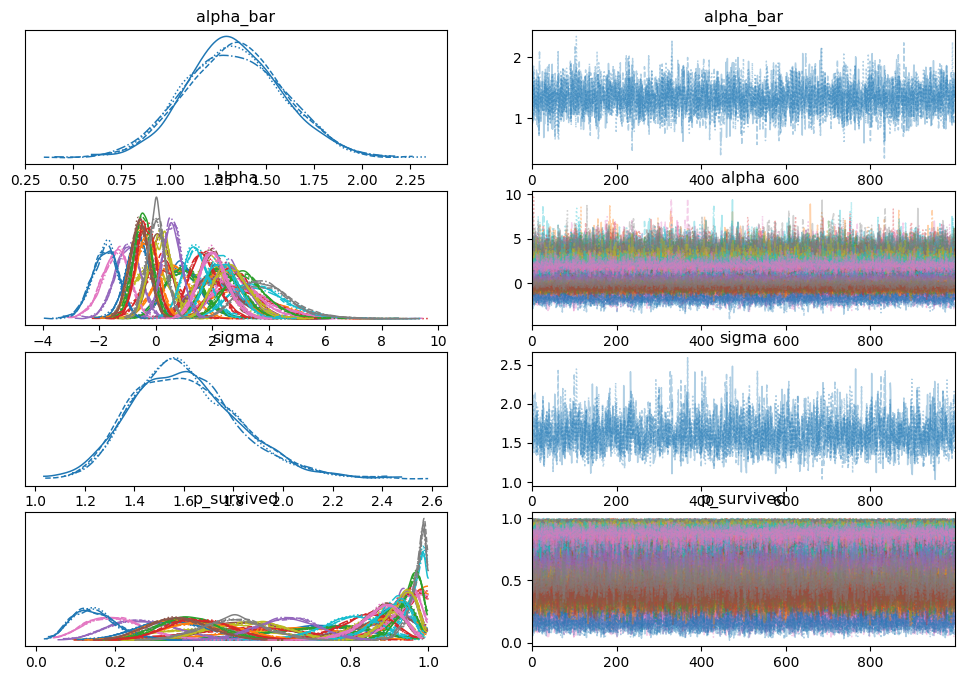

In [46]:
az.plot_trace(model_2_trace)

[autoreload of _pydevd_bundle failed: Traceback (most recent call last):
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 325, in check
    superreload(m, reload, self.old_objects)
    ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 580, in superreload
    module = reload(module)
  File "/Users/shenglong/.local/share/uv/python/cpython-3.13.9-macos-x86_64-none/lib/python3.13/importlib/__init__.py", line 128, in reload
    raise ModuleNotFoundError(f"spec not found for the module {name!r}", name=name)
ModuleNotFoundError: spec not found for the module '_pydevd_bundle'
]
[autoreload of _pydev_bundle failed: Traceback (most recent call last):
  File "/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/IPython/extensions/autoreload.py", line 325, in check
    s

<Axes: xlabel='survived'>

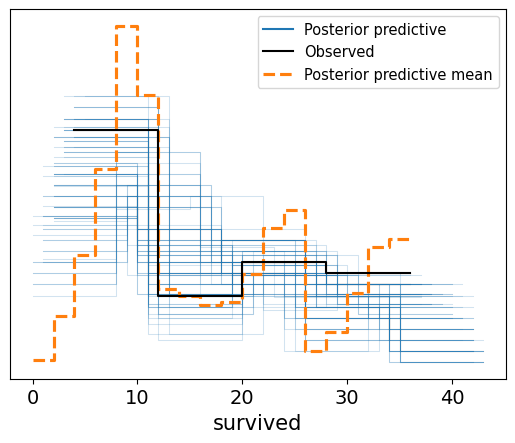

In [48]:
# pp check 
az.plot_ppc(model_2_trace, num_pp_samples=100)

In [ ]:
# the following does not quite work ... 
# need more work to figure out how to plot ecdf ... 
# az.plot_ecdf(model_1_trace)

# Model comparison 

In [37]:
az.compare({'unpooled': model_1_trace, 'pooled': model_2_trace})

/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(
/Users/shenglong/Downloads/mika-long.github.io/.venv/lib/python3.13/site-packages/arviz/stats/stats.py:797: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
pooled,0,-111.837417,32.723596,0.000000,1.000000e+00,4.393536,0.000000,True,log
unpooled,1,-120.397906,38.878672,8.560489,3.463896e-14,2.334387,3.321347,True,log


Observe that the `pooled` model is better than the `unpooled` model. 

Of course, the above example is "easy" as it does not involve complex grouping, as each row was its own group. Next we will explore the chimpanzee dataset for something a bit more complex to demonstrate the power of the `PyMC` syntax. 

The chimpanzee data is obtained from [here](). 

Here's the math model: 
$$
\begin{align}
TODO
\end{align}$$